In [7]:
from stixdcpy.quicklook import LightCurves
import matplotlib.pyplot as plt


In [2]:
lc = LightCurves.from_sdc(start_utc='2023-07-16T02:00:00', end_utc='2023-07-16T10:00:00', ltc=True)


In [3]:
lc

In [5]:
lc.data.keys()

dict_keys(['cqllc', 'rcr', 'triggers', 'energy_bins', 'num', 'start_unix', 'start_utc', 'end_unix', 'end_utc', 'light_time_diff', 'solo_to_earth_light_time', 'is_light_time_corrected', 'delta_time', 'counts'])

In [10]:
lc.data['energy_bins']

{'names': ['4 – 10 keV',
  '10 – 15 keV',
  '15 – 25 keV',
  '25 – 50 keV',
  '50 – 84 keV'],
 'sci_bin_edges': [[1, 7], [7, 12], [12, 17], [17, 23], [23, 28]]}

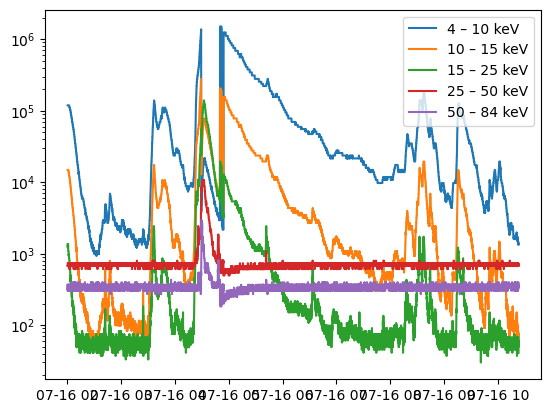

In [14]:
fig=plt.figure()
for i, this_bin in enumerate(lc.data['energy_bins']['names']):
    plt.plot(lc.time, lc.counts[i,:], label=this_bin)
plt.legend()
plt.yscale('log')


In [18]:
from astropy.time import Time, TimeDelta
import astropy.units as u

In [57]:
dt = TimeDelta(1 * u.hr)
delay = TimeDelta(10 * u.hr)
now = Time.now()
tr = [now - delay - dt, now - delay]
lc = LightCurves.from_sdc(start_utc=tr[0].isot, end_utc=tr[1].isot, ltc=True)
if lc.data:
    print(len(lc.counts[0, :]))

580


In [47]:
from astropy.timeseries import TimeSeries

In [55]:
stix_ts = TimeSeries(time = lc.time, data={f'qlc{i}': this_data for i, this_data in enumerate(lc.counts)})
stix_ts

time,qlc0,qlc1,qlc2,qlc3,qlc4
Time,int64,int64,int64,int64,int64
2025-09-12 07:44:38.480000,495,49,33,607,271
2025-09-12 07:44:42.480000,495,45,53,607,271
2025-09-12 07:44:46.480000,495,37,53,607,303
2025-09-12 07:44:50.480000,495,49,49,543,303
2025-09-12 07:44:54.480000,543,45,41,607,271
2025-09-12 07:44:58.480000,543,49,41,607,303
2025-09-12 07:45:02.480000,607,67,53,607,303
2025-09-12 07:45:06.480000,671,53,53,607,303
2025-09-12 07:45:10.480000,671,49,49,607,271


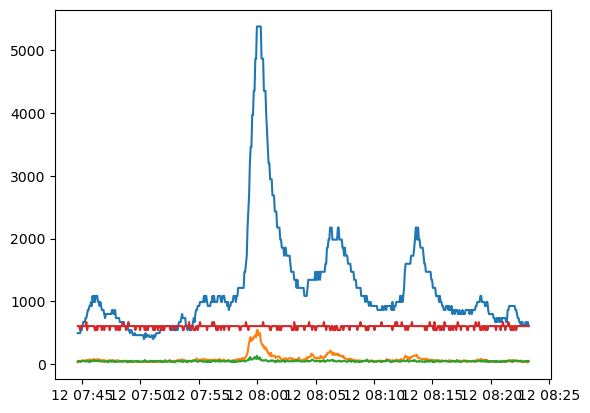

In [54]:
plt.plot(stix_ts.time.to_datetime(), stix_ts['channel0'])
plt.plot(stix_ts.time.to_datetime(), stix_ts['channel1'])
plt.plot(stix_ts.time.to_datetime(), stix_ts['channel2'])
plt.plot(stix_ts.time.to_datetime(), stix_ts['channel3'])